Imports, configuration and dataset validation

In [1]:
from pathlib import Path
import random
import yaml
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from ultralytics import YOLO

DATASET_DIR = Path(r"D:\Projects\cv_project\void_detection\data")
DEVICE = 0 if torch.cuda.is_available() else "cpu"

with open(DATASET_DIR / "data.yaml", encoding="utf-8") as f:
    data = yaml.safe_load(f)

data.update({
    "path": str(DATASET_DIR.resolve()),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images"
})

TRAIN_YAML = DATASET_DIR / "data_train.yaml"
with open(TRAIN_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(data, f, sort_keys=False)

for split in ("train", "valid", "test"):
    images = DATASET_DIR / split / "images"
    labels = DATASET_DIR / split / "labels"
    print(f"{split}: {len(list(images.glob('*')))} images, "
          f"{len(list(labels.glob('*.txt')))} labels")

print("PyTorch:", torch.__version__)
print("Device:", torch.cuda.get_device_name(0) if DEVICE == 0 else "CPU")
print("Classes:", data["names"])

train: 506 images, 506 labels
valid: 19 images, 19 labels
test: 11 images, 11 labels
PyTorch: 2.14.1+cu126
Device: NVIDIA GeForce RTX 4050 Laptop GPU
Classes: ['void_detection - v1 2025-04-06 7-16pm']


Training the model

In [2]:
model = YOLO("yolo11s.pt")

results = model.train(
    data=str(TRAIN_YAML),
    epochs=50,
    imgsz=640,
    batch=8,
    device=DEVICE,
    workers=4,
    project="runs/void_detection",
    name="yolo11s_baseline",
    patience=10,
    seed=42,
    plots=True
)

BEST_MODEL = Path(results.save_dir) / "weights" / "best.pt"
model = YOLO(str(BEST_MODEL))

print("Best model:", BEST_MODEL)

Ultralytics 8.4.188  Python-3.12.10 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\Projects\cv_project\void_detection\data\data_train.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11s

Model Evaluation

In [3]:
metrics = model.val(
    data=str(TRAIN_YAML),
    split="test",
    imgsz=640,
    batch=8,
    device=DEVICE,
    plots=True
)

print(f"mAP50:    {metrics.box.map50:.4f}")
print(f"mAP50-95: {metrics.box.map:.4f}")

Ultralytics 8.4.188  Python-3.12.10 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 219.5±59.4 MB/s, size: 78.3 KB)
val: Scanning D:\Projects\cv_project\void_detection\data\test\labels.cache... 11 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 11/11  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.6s/it 3.2s9.8s
                   all         11         64      0.766      0.765      0.799      0.391
Speed: 4.6ms preprocess, 46.1ms inference, 0.0ms loss, 1.3ms postprocess per image
Results saved to D:\Projects\cv_project\void_detection\runs\detect\val
mAP50:    0.7988
mAP50-95: 0.3908


Predict a random test image

Results saved to D:\Projects\cv_project\void_detection\runs\detect\predict


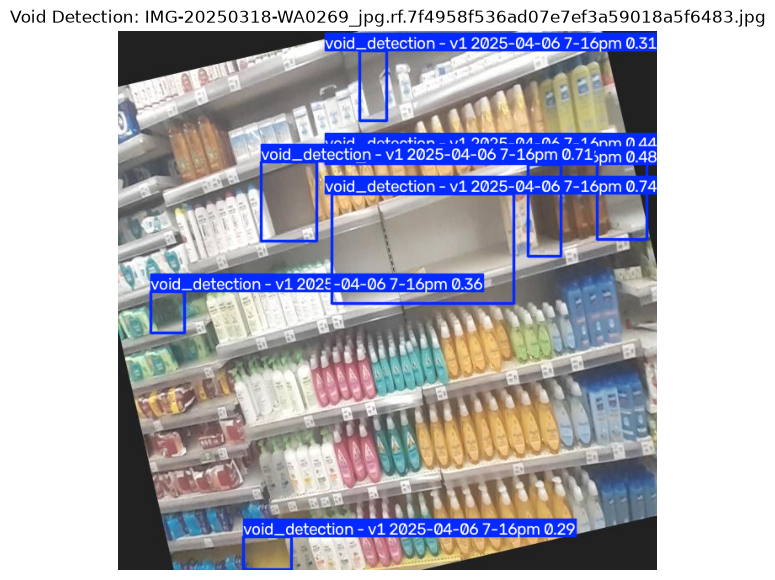

Predicted detections: 7


In [4]:
test_images = [
    p for p in (DATASET_DIR / "test" / "images").iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
]

if not test_images:
    raise FileNotFoundError("No test images found.")

image_path = random.choice(test_images)
prediction = model.predict(
    source=str(image_path),
    imgsz=640,
    conf=0.25,
    device=DEVICE,
    save=True,
    verbose=False
)[0]

plt.figure(figsize=(10, 7))
plt.imshow(prediction.plot()[..., ::-1])
plt.title(f"Void Detection: {image_path.name}")
plt.axis("off")
plt.show()

print("Predicted detections:", len(prediction.boxes))

Compare ground truth vs predicted voids

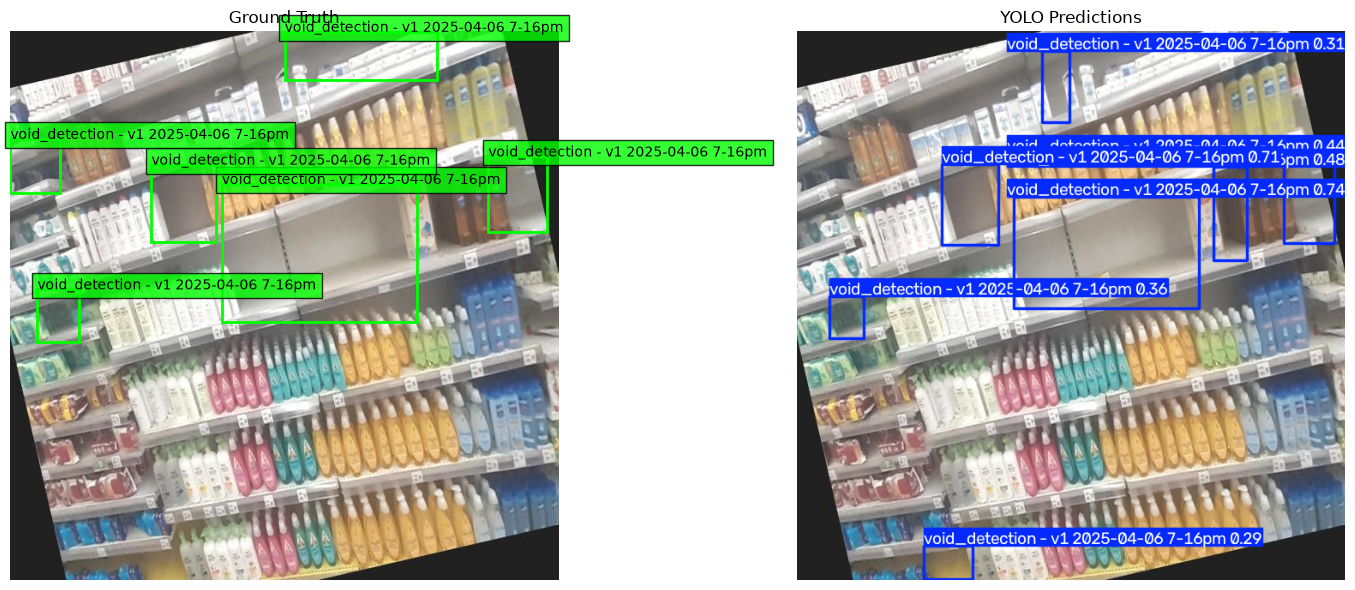

Ground-truth label: D:\Projects\cv_project\void_detection\data\test\labels\IMG-20250318-WA0269_jpg.rf.7f4958f536ad07e7ef3a59018a5f6483.txt
Predicted detections: 7


In [5]:
image = plt.imread(image_path)
label_path = DATASET_DIR / "test" / "labels" / f"{image_path.stem}.txt"
height, width = image.shape[:2]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(image)
axes[0].set_title("Ground Truth")

if label_path.is_file():
    for line in label_path.read_text().splitlines():
        values = line.split()
        if len(values) != 5:
            continue

        cls, xc, yc, bw, bh = map(float, values)
        x, y = (xc - bw / 2) * width, (yc - bh / 2) * height
        bw, bh = bw * width, bh * height

        axes[0].add_patch(Rectangle(
            (x, y), bw, bh, fill=False, edgecolor="lime", linewidth=2
        ))
        axes[0].text(x, y, model.names.get(int(cls), str(int(cls))),
                     color="black", bbox=dict(facecolor="lime", alpha=0.8))
else:
    axes[0].text(0.5, 0.5, "No ground-truth labels",
                 transform=axes[0].transAxes, ha="center")

axes[1].imshow(prediction.plot()[..., ::-1])
axes[1].set_title("YOLO Predictions")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Ground-truth label:", label_path)
print("Predicted detections:", len(prediction.boxes))